# Task 1 y Task 2 — Competencia entre dos plataformas

Se estudia el modelo de competencia entre dos plataformas digitales:

$$\dot{x} = r_1 x (1 - x - \alpha_{12} y), \qquad \dot{y} = r_2 y (1 - y - \alpha_{21} x)$$

- $x(t)$ y $y(t)$: base de usuarios de las plataformas A y B (como fracción de su capacidad de mercado).
- $r_1, r_2$: tasas de crecimiento.
- $\alpha_{12}$: cuánto frena B a A. $\alpha_{21}$: cuánto frena A a B.

**Grupo 10** → conjunto 2: $\alpha_{12} = 1.4$, $\alpha_{21} = 1.5$, $r_1 = 1$, $r_2 = 0.9$.

Las funciones del modelo (campo, jacobiana, equilibrios, clasificación) se encuentran en `competencia.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from competencia import campo, clasificar, equilibrios, jacobiana

A12, A21, R1, R2 = 1.4, 1.5, 1.0, 0.9
PARAMS = (A12, A21, R1, R2)
SEMILLA = 42
rng = np.random.default_rng(SEMILLA)

ESTADOS = {"P1": (0.05, 0.05), "P2": (0.80, 0.30), "P3": (0.30, 0.80), "P4": (0.60, 0.60)}

## Task 1.2. Clasificación de los equilibrios

Para cada equilibrio se evalúa la jacobiana $J$ y se calculan la traza $\tau$, el determinante $\Delta$, el discriminante $\tau^2 - 4\Delta$ y los valores propios $\lambda$. Esta tabla solo verifica los cálculos hechos a mano en el documento.

In [2]:
eq = equilibrios(A12, A21)
clase = {}
for nombre, p in eq.items():
    clase[nombre] = clasificar(jacobiana(p, *PARAMS))
    c = clase[nombre]
    print(f"{nombre:>9} ({p[0]:.4f}, {p[1]:.4f}) | τ = {c['τ']:+.4f} | Δ = {c['Δ']:+.4f} | "
          f"τ²-4Δ = {c['τ²-4Δ']:+.4f} | λ = {np.round(c['λ'].real, 4)} | {c['tipo']}")

    (0,0) (0.0000, 0.0000) | τ = +1.9000 | Δ = +0.9000 | τ²-4Δ = +0.0100 | λ = [1.  0.9] | nodo inestable
    (1,0) (1.0000, 0.0000) | τ = -1.4500 | Δ = +0.4500 | τ²-4Δ = +0.3025 | λ = [-1.   -0.45] | nodo estable
    (0,1) (0.0000, 1.0000) | τ = -1.3000 | Δ = +0.3600 | τ²-4Δ = +0.2500 | λ = [-0.9 -0.4] | nodo estable
 interior (0.3636, 0.4545) | τ = -0.7727 | Δ = -0.1636 | τ²-4Δ = +1.2517 | λ = [ 0.173  -0.9458] | silla


### Plano traza-determinante

Debajo de la parábola $\tau^2 = 4\Delta$ se ubican los nodos y encima los focos. Con $\Delta < 0$ el equilibrio es una silla; con $\Delta > 0$, el signo de $\tau$ indica si es estable ($\tau < 0$) o inestable ($\tau > 0$).

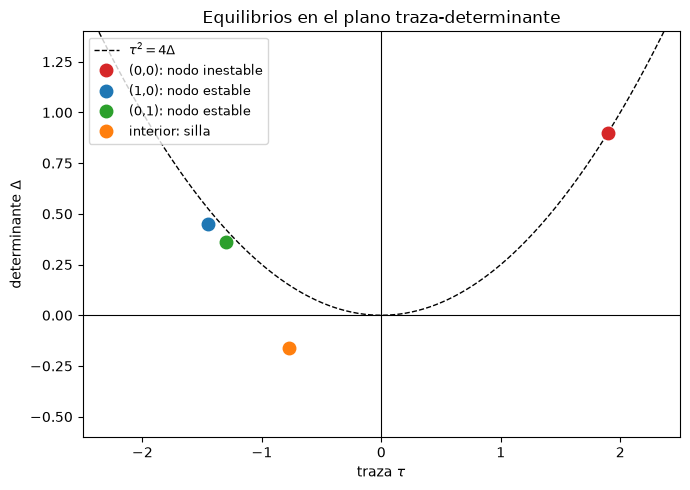

In [3]:
COLORES = {"(0,0)": "tab:red", "(1,0)": "tab:blue", "(0,1)": "tab:green", "interior": "tab:orange"}

fig, ax = plt.subplots(figsize=(7, 5))
t = np.linspace(-2.5, 2.5, 400)
ax.plot(t, t**2 / 4, "k--", lw=1, label=r"$\tau^2 = 4\Delta$")
ax.axhline(0, color="k", lw=0.8)
ax.axvline(0, color="k", lw=0.8)
for nombre, c in clase.items():
    ax.plot(c["τ"], c["Δ"], "o", ms=9, color=COLORES[nombre], label=f"{nombre}: {c['tipo']}")
ax.set_xlim(-2.5, 2.5)
ax.set_ylim(-0.6, 1.4)
ax.set_xlabel(r"traza $\tau$")
ax.set_ylabel(r"determinante $\Delta$")
ax.set_title("Equilibrios en el plano traza-determinante")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig("figuras/traza_determinante.png", dpi=150)
plt.show()

## Task 1.3. Nulclinas y dirección del campo

Las **nulclinas** son las curvas donde una de las derivadas vale cero:

- Nulclinas de $x$ ($\dot{x} = 0$): $x = 0$ y $x + 1.4y = 1$.
- Nulclinas de $y$ ($\dot{y} = 0$): $y = 0$ y $y + 1.5x = 1$.

Sus intersecciones son los equilibrios. En cada región se dibuja una flecha según los signos de $\dot{x}$ y $\dot{y}$.

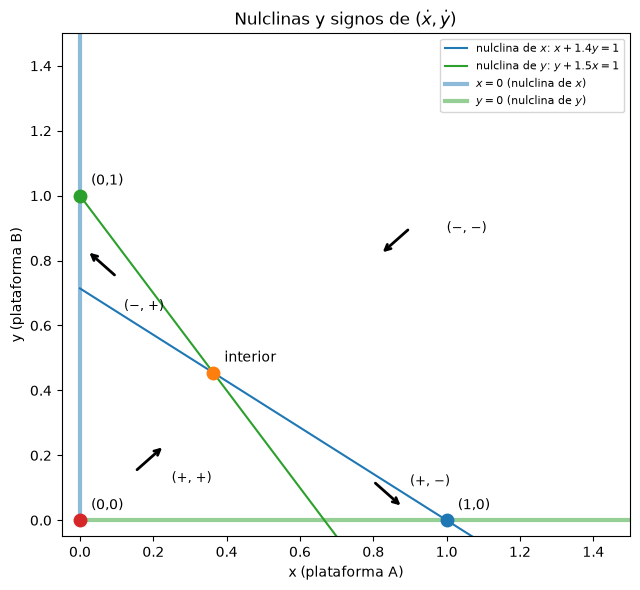

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 6))
xs = np.linspace(0, 1.5, 200)
ax.plot(xs, (1 - xs) / A12, color="tab:blue", label=r"nulclina de $x$: $x + 1.4y = 1$")
ax.plot(xs, 1 - A21 * xs, color="tab:green", label=r"nulclina de $y$: $y + 1.5x = 1$")
ax.plot([0, 0], [0, 1.5], color="tab:blue", lw=3, alpha=0.5, label=r"$x = 0$ (nulclina de $x$)")
ax.plot([0, 1.5], [0, 0], color="tab:green", lw=3, alpha=0.5, label=r"$y = 0$ (nulclina de $y$)")

for nombre, p in eq.items():
    ax.plot(*p, "o", ms=9, color=COLORES[nombre], zorder=5)
    ax.annotate(nombre, p, textcoords="offset points", xytext=(8, 8))

# Una flecha por región, con la dirección dada por los signos de (dx/dt, dy/dt)
REGIONES = [((0.15, 0.15), (0.25, 0.13)), ((0.9, 0.9), (1.0, 0.9)),
            ((0.8, 0.12), (0.9, 0.12)), ((0.1, 0.75), (0.12, 0.66))]
for p, pos_texto in REGIONES:
    dx, dy = np.sign(campo(p, *PARAMS))
    ax.annotate("", xy=(p[0] + 0.08 * dx, p[1] + 0.08 * dy), xytext=p,
                arrowprops=dict(arrowstyle="->", lw=2, color="k"))
    ax.text(*pos_texto, f"({'+' if dx > 0 else '−'}, {'+' if dy > 0 else '−'})", va="center", fontsize=9)

ax.set_xlim(-0.05, 1.5)
ax.set_ylim(-0.05, 1.5)
ax.set_xlabel("x (plataforma A)")
ax.set_ylabel("y (plataforma B)")
ax.set_title(r"Nulclinas y signos de $(\dot{x}, \dot{y})$")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.savefig("figuras/nulclinas.png", dpi=150)
plt.show()

## Task 2.1. Euler y Runge-Kutta 4

Ambos métodos avanzan el estado en pasos de tamaño $h$:

- **Euler**: $x_{k+1} = x_k + h\,f(x_k)$. Error global de orden 1.
- **RK4**: promedia cuatro pendientes dentro del paso. Error global de orden 4.

Se implementan en `competencia.py` (`euler` y `rk4`) sin usar funciones de integración de librerías. Como referencia se usa `solve_ivp` (método `DOP853`, tolerancias $10^{-12}$) desde P2 hasta $T = 10$.

In [5]:
from scipy.integrate import solve_ivp

from competencia import destino, euler, rk4

f = lambda x: campo(x, *PARAMS)

T = 10
x0 = np.array(ESTADOS["P2"])
ref = solve_ivp(lambda t, x: f(x), (0, T), x0, method="DOP853", rtol=1e-12, atol=1e-12).y[:, -1]

pasos = np.array([0.2, 0.1, 0.05, 0.025, 0.0125])
err_euler = np.array([np.linalg.norm(euler(f, x0, h, T)[1][-1] - ref) for h in pasos])
err_rk4 = np.array([np.linalg.norm(rk4(f, x0, h, T)[1][-1] - ref) for h in pasos])

print(f"Referencia x(10) = {ref}")
print(f"{'h':>8} | {'error Euler':>12} | {'error RK4':>12}")
for h, e1, e4 in zip(pasos, err_euler, err_rk4):
    print(f"{h:>8} | {e1:>12.3e} | {e4:>12.3e}")

Referencia x(10) = [0.97288889 0.01131331]
       h |  error Euler |    error RK4
     0.2 |    2.661e-03 |    1.679e-08
     0.1 |    1.328e-03 |    7.623e-10
    0.05 |    6.636e-04 |    4.006e-11
   0.025 |    3.317e-04 |    2.132e-12
  0.0125 |    1.658e-04 |    7.178e-14


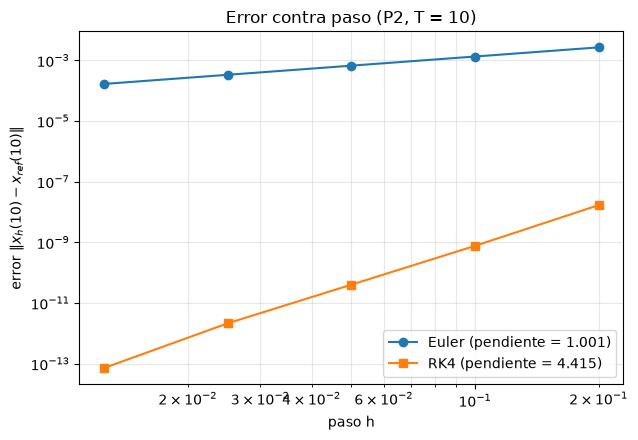

Pendiente Euler: 1.0011 (teórica 1)
Pendiente RK4:   4.4153 (teórica 4)
Pendiente local de RK4 entre pasos consecutivos: [4.461 4.25  4.232 4.893]


In [6]:
pend_euler = np.polyfit(np.log(pasos), np.log(err_euler), 1)[0]
pend_rk4 = np.polyfit(np.log(pasos), np.log(err_rk4), 1)[0]

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.loglog(pasos, err_euler, "o-", label=f"Euler (pendiente = {pend_euler:.3f})")
ax.loglog(pasos, err_rk4, "s-", label=f"RK4 (pendiente = {pend_rk4:.3f})")
ax.set_xlabel("paso h")
ax.set_ylabel(r"error $\|x_h(10) - x_{ref}(10)\|$")
ax.set_title("Error contra paso (P2, T = 10)")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Pendiente Euler: {pend_euler:.4f} (teórica 1)")
print(f"Pendiente RK4:   {pend_rk4:.4f} (teórica 4)")
print("Pendiente local de RK4 entre pasos consecutivos:",
      np.round(np.diff(np.log(err_rk4)) / np.diff(np.log(pasos)), 3))

**RESULTADOS**

La pendiente de Euler es $1.0011$, prácticamente igual a su orden teórico 1. La de RK4 es $4.4153$, algo mayor que 4. Las pendientes locales explican la desviación:

- Entre $h = 0.2$ y $h = 0.1$ la pendiente es $4.461$: con pasos grandes, los términos de error de orden mayor que $h^4$ todavía pesan.
- En los pasos intermedios se acerca a 4 ($4.25$ y $4.232$).
- Entre $h = 0.025$ y $h = 0.0125$ sube a $4.893$: el error de RK4 ($7.2 \times 10^{-14}$) ya es menor que la tolerancia de la referencia ($10^{-12}$) y cercano al redondeo de punto flotante, por lo que el error medido deja de ser solo el del método.

## Task 2.2. Retrato de fases

Se dibuja el campo vectorial con flechas normalizadas (solo indican dirección), las nulclinas y trayectorias calculadas con RK4 ($h = 0.01$, $T = 40$) desde estados iniciales repartidos en el cuadrante, incluidos estados muy cerca de los ejes.

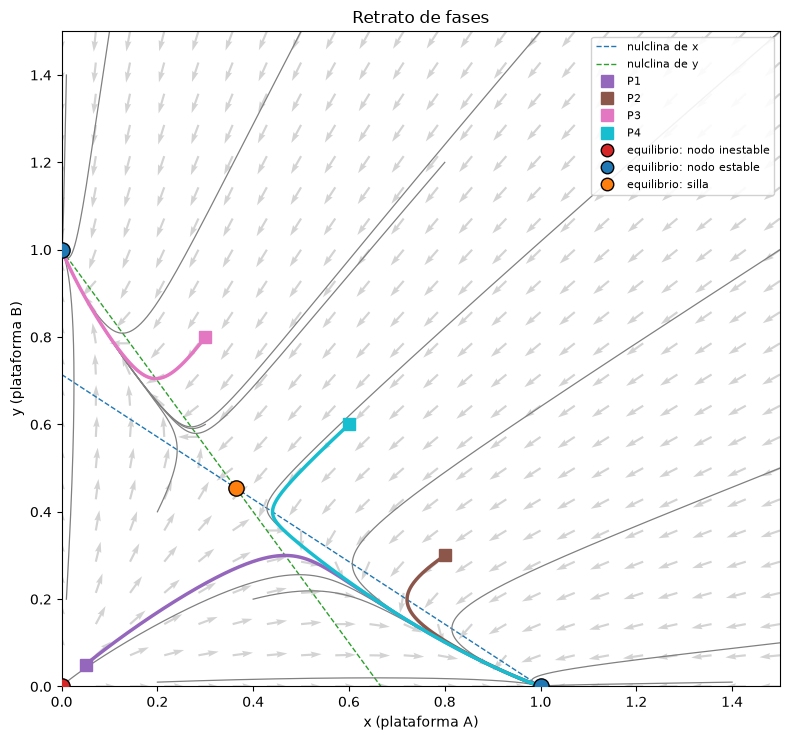

P1 (0.05, 0.05) -> estado en t = 40: (1.0000, 0.0000)
P2 (0.8, 0.3) -> estado en t = 40: (1.0000, 0.0000)
P3 (0.3, 0.8) -> estado en t = 40: (0.0000, 1.0000)
P4 (0.6, 0.6) -> estado en t = 40: (1.0000, 0.0000)


In [7]:
H, T_FASES = 0.01, 40
iniciales = [(0.01, 0.2), (0.01, 1.4), (0.2, 0.01), (1.4, 0.01), (0.01, 0.01),
             (0.1, 1.5), (0.5, 1.5), (1.0, 1.5), (1.5, 1.5), (1.5, 1.0), (1.5, 0.5),
             (1.5, 0.1), (0.2, 0.4), (0.4, 0.2), (0.3, 0.6), (0.8, 1.2)]
TIPO_COLOR = {"nodo inestable": "tab:red", "nodo estable": "tab:blue", "silla": "tab:orange"}
P_COLOR = {"P1": "tab:purple", "P2": "tab:brown", "P3": "tab:pink", "P4": "tab:cyan"}

fig, ax = plt.subplots(figsize=(8, 7.5))
g = np.linspace(0, 1.5, 22)
GX, GY = np.meshgrid(g, g)
U, V = campo((GX, GY), *PARAMS)
norma = np.hypot(U, V)
norma[norma == 0] = 1
ax.quiver(GX, GY, U / norma, V / norma, color="lightgray", scale=35, width=0.003)

xs = np.linspace(0, 1.5, 200)
ax.plot(xs, (1 - xs) / A12, color="tab:blue", ls="--", lw=1, label="nulclina de x")
ax.plot(xs, 1 - A21 * xs, color="tab:green", ls="--", lw=1, label="nulclina de y")

for p in iniciales:
    _, X = rk4(f, np.array(p), H, T_FASES)
    ax.plot(X[:, 0], X[:, 1], color="gray", lw=0.9)

finales = {}
for nombre, p in ESTADOS.items():
    _, X = rk4(f, np.array(p), H, T_FASES)
    finales[nombre] = X[-1]
    ax.plot(X[:, 0], X[:, 1], color=P_COLOR[nombre], lw=2.5)
    ax.plot(*p, "s", ms=8, color=P_COLOR[nombre], label=nombre)

for nombre, p in eq.items():
    tipo = clase[nombre]["tipo"]
    ax.plot(*p, "o", ms=11, color=TIPO_COLOR[tipo], mec="k", zorder=5)
for tipo, color in TIPO_COLOR.items():
    ax.plot([], [], "o", ms=9, color=color, mec="k", label=f"equilibrio: {tipo}")

ax.set_xlim(0, 1.5)
ax.set_ylim(0, 1.5)
ax.set_xlabel("x (plataforma A)")
ax.set_ylabel("y (plataforma B)")
ax.set_title("Retrato de fases")
ax.legend(loc="upper right", fontsize=8, framealpha=0.9)
plt.tight_layout()
plt.show()

for nombre, xf in finales.items():
    print(f"{nombre} {ESTADOS[nombre]} -> estado en t = {T_FASES}: ({xf[0]:.4f}, {xf[1]:.4f})")

### Comparación con las predicciones del Task 1.3

| Estado | Predicción | Simulación ($t = 40$) | ¿Coincide? |
|---|---|---|---|
| P1 $(0.05, 0.05)$ | $(1,0)$, baja confianza | $(1,0)$ | Sí |
| P2 $(0.80, 0.30)$ | $(1,0)$ | $(1,0)$ | Sí |
| P3 $(0.30, 0.80)$ | $(0,1)$ | $(0,1)$ | Sí |
| P4 $(0.60, 0.60)$ | $(1,0)$ | $(1,0)$ | Sí |

No hubo discrepancias. La predicción menos segura fue **P1**. Acertó porque cerca del origen A crece más rápido ($\lambda = 1$ contra $0.9$) y frena más a B ($\alpha_{21} = 1.5 > \alpha_{12} = 1.4$): en la figura, la trayectoria de P1 pasa por debajo de la silla y termina en $(1,0)$. Sin embargo, el margen fue pequeño, la frontera calculada en el Task 2.3 pasa por $x = 0.032$ en $y = 0.05$, a solo $0.018$ de P1, y está más cerca de P1 que lo estimado con la recta del vector propio ($y \approx 0.096$ en $x = 0.05$), porque la frontera se curva lejos de la silla.

## Task 2.3. Mapa de cuencas

Se simulan $60 \times 60$ estados iniciales uniformes en $[0.01, 1.5]^2$ con RK4 ($h = 0.05$).

**Criterio de convergencia:** un estado se asigna a un equilibrio estable cuando su distancia a él es menor que $10^{-4}$. Esta distancia es mucho menor que la distancia entre los equilibrios estables y la silla, y dentro de esa vecindad la linealización garantiza que el estado ya no sale (ambos valores propios son negativos). Se fija un tiempo máximo de $t = 500$; los estados que no cumplen el criterio se marcan como no convergidos.

In [8]:
ATRACTORES = [eq["(1,0)"], eq["(0,1)"]]
NOMBRES_ATR = ["(1,0): gana A", "(0,1): gana B"]

n = 60
malla = np.linspace(0.01, 1.5, n)
MX, MY = np.meshgrid(malla, malla)
X0 = np.column_stack([MX.ravel(), MY.ravel()])
etiqueta, t_conv = destino(f, X0, 0.05, 500, ATRACTORES)
cuenca = etiqueta.reshape(n, n)

for i, nombre in enumerate(NOMBRES_ATR):
    print(f"Fracción de la cuenca de {nombre}: {np.mean(etiqueta == i):.4f}")
print(f"No convergidos: {np.sum(etiqueta == -1)}")
print(f"Tiempo máximo de convergencia: {np.nanmax(t_conv):.2f}")

Fracción de la cuenca de (1,0): gana A: 0.5739
Fracción de la cuenca de (0,1): gana B: 0.4261
No convergidos: 0
Tiempo máximo de convergencia: 73.55


**RESULTADOS**

Todos los estados convergieron antes de $t = 500$ (el más lento tardó $73.55$). La cuenca de $(1,0)$ ocupa el **57.39%** de la malla y la de $(0,1)$ el **42.61%**.

### Frontera entre cuencas por bisección

Se toman segmentos horizontales $y = c$, con $x \in [0.01, 1.5]$. En el extremo izquierdo el estado va a $(0,1)$ y en el derecho a $(1,0)$; la bisección reduce el intervalo hasta un ancho de $10^{-6}$.

In [9]:
def va_a_A(p):
    # True si el estado p converge a (1,0)
    return destino(f, np.array([p]), 0.05, 500, ATRACTORES)[0][0] == 0


def biseccion_frontera(c, a=0.01, b=1.5, tol=1e-6):
    # Punto x de la frontera sobre el segmento y = c
    while b - a > tol:
        m = (a + b) / 2
        if va_a_A((m, c)):
            b = m
        else:
            a = m
    return (a + b) / 2


niveles = np.array([0.05, 0.15, 0.3, 0.4, 0.45, 0.5, 0.6, 0.8, 1.1, 1.4])
frontera = np.array([[biseccion_frontera(c), c] for c in niveles])
for xb, c in frontera:
    print(f"y = {c:.2f} -> x frontera = {xb:.6f}")

y = 0.05 -> x frontera = 0.032030
y = 0.15 -> x frontera = 0.107712
y = 0.30 -> x frontera = 0.230720
y = 0.40 -> x frontera = 0.316188
y = 0.45 -> x frontera = 0.359663
y = 0.50 -> x frontera = 0.403553
y = 0.60 -> x frontera = 0.492416
y = 0.80 -> x frontera = 0.673659
y = 1.10 -> x frontera = 0.952144
y = 1.40 -> x frontera = 1.236515


Vector propio estable: [0.65831518 0.7527424 ], λ = -0.9458
Pendiente del vector propio:          1.1434
Pendiente numérica cerca de la silla: 1.1446


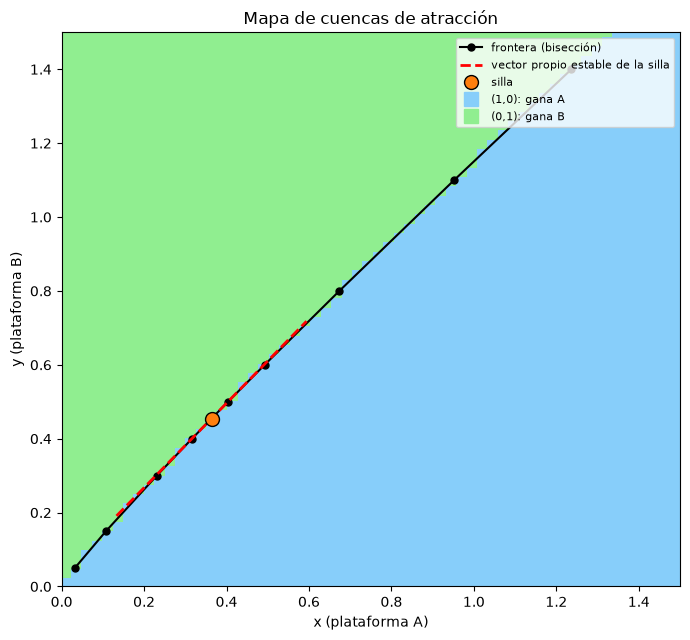

In [10]:
silla = eq["interior"]
lam, vec = np.linalg.eig(jacobiana(silla, *PARAMS))
v_estable = vec[:, np.argmin(lam.real)].real
pend_teorica = v_estable[1] / v_estable[0]

# Pendiente numérica de la frontera con los dos puntos más cercanos a la silla (y = 0.4 y y = 0.5)
p1, p2 = frontera[niveles == 0.4][0], frontera[niveles == 0.5][0]
pend_numerica = (p2[1] - p1[1]) / (p2[0] - p1[0])
print(f"Vector propio estable: {v_estable}, λ = {lam.real.min():.4f}")
print(f"Pendiente del vector propio:          {pend_teorica:.4f}")
print(f"Pendiente numérica cerca de la silla: {pend_numerica:.4f}")

from matplotlib.colors import ListedColormap

fig, ax = plt.subplots(figsize=(7, 6.5))
ax.pcolormesh(MX, MY, cuenca, cmap=ListedColormap(["lightgray", "lightskyblue", "lightgreen"]),
              vmin=-1, vmax=1, shading="auto")
ax.plot(frontera[:, 0], frontera[:, 1], "ko-", ms=5, label="frontera (bisección)")
s = np.linspace(-0.35, 0.35, 10)
ax.plot(silla[0] + s * v_estable[0], silla[1] + s * v_estable[1], "r--", lw=2, label="vector propio estable de la silla")
ax.plot(*silla, "o", color="tab:orange", mec="k", ms=10, label="silla")
ax.plot([], [], "s", color="lightskyblue", ms=10, label=NOMBRES_ATR[0])
ax.plot([], [], "s", color="lightgreen", ms=10, label=NOMBRES_ATR[1])
ax.set_xlim(0, 1.5)
ax.set_ylim(0, 1.5)
ax.set_xlabel("x (plataforma A)")
ax.set_ylabel("y (plataforma B)")
ax.set_title("Mapa de cuencas de atracción")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

**RESULTADOS**

La frontera numérica sale del origen, pasa por la silla y sigue casi en línea recta hacia arriba a la derecha. Cerca de la silla, su pendiente ($1.1446$) coincide con la del vector propio asociado al valor propio negativo $\lambda = -0.9458$ ($1.1434$): la frontera es tangente a esa dirección, es decir, es la variedad estable de la silla. Lejos de la silla se separa levemente de la recta (por ejemplo, en $y = 0.05$ la frontera está en $x = 0.032$).

## Task 2.4. Recuperación ante perturbaciones pequeñas

Cada equilibrio estable se perturba una distancia de $10^{-4}$ en ocho direcciones igualmente espaciadas que mantienen $x, y \ge 0$. Como ambos equilibrios están sobre un eje, se usan ángulos en $[0°, 180°]$ para $(1,0)$ (requiere $y \ge 0$) y en $[-90°, 90°]$ para $(0,1)$ (requiere $x \ge 0$). Se simula con RK4 y se ajusta una recta a $\ln\|x(t) - x^*\|$ en la ventana donde la norma cae de $10^{-4}$ a $10^{-6}$; la tasa de decaimiento es menos la pendiente.

In [11]:
def tasa_decaimiento(x_eq, angulo, d_max=1e-4, d_min=1e-6, h=0.01, T=80):
    # Tasa de decaimiento ajustada en la ventana d_min <= ||x - x*|| <= d_max
    x0 = x_eq + 1e-4 * np.array([np.cos(angulo), np.sin(angulo)])
    t, X = rk4(f, x0, h, T)
    d = np.linalg.norm(X - x_eq, axis=1)
    ventana = (d <= d_max) & (d >= d_min)
    return -np.polyfit(t[ventana], np.log(d[ventana]), 1)[0]


casos = {"(1,0)": np.linspace(0, np.pi, 8), "(0,1)": np.linspace(-np.pi / 2, np.pi / 2, 8)}
tasas = {}
for nombre, angulos in casos.items():
    teorica = np.abs(clase[nombre]["λ"].real).min()
    tasas[nombre] = np.array([tasa_decaimiento(eq[nombre], a) for a in angulos])
    tardias = np.array([tasa_decaimiento(eq[nombre], a, 1e-8, 1e-11) for a in angulos])
    print(f"Equilibrio {nombre}: min|Re λ| = {teorica:.4f}")
    print(f"  {'ángulo':>8} | {'tasa [1e-4, 1e-6]':>17} | {'error rel.':>10} | {'tasa [1e-8, 1e-11]':>18} | {'error rel.':>10}")
    for a, k, kt in zip(angulos, tasas[nombre], tardias):
        print(f"  {np.degrees(a):7.2f}° | {k:>17.4f} | {abs(k - teorica) / teorica:>10.2%} | "
              f"{kt:>18.4f} | {abs(kt - teorica) / teorica:>10.2%}")

Equilibrio (1,0): min|Re λ| = 0.4500
    ángulo | tasa [1e-4, 1e-6] | error rel. | tasa [1e-8, 1e-11] | error rel.
     0.00° |            1.0000 |    122.23% |             1.0000 |    122.22%
    25.71° |            0.3680 |     18.22% |             0.4500 |      0.00%
    51.43° |            0.3818 |     15.16% |             0.4500 |      0.00%
    77.14° |            0.3933 |     12.59% |             0.4500 |      0.00%
   102.86° |            0.4023 |     10.61% |             0.4500 |      0.00%
   128.57° |            0.4162 |      7.51% |             0.4500 |      0.00%
   154.29° |            0.4393 |      2.37% |             0.4500 |      0.00%
   180.00° |            1.0000 |    122.22% |             1.0000 |    122.22%


Equilibrio (0,1): min|Re λ| = 0.4000
    ángulo | tasa [1e-4, 1e-6] | error rel. | tasa [1e-8, 1e-11] | error rel.
   -90.00° |            0.9000 |    125.00% |             0.9000 |    125.00%
   -64.29° |            0.3881 |      2.97% |             0.4000 |      0.00%
   -38.57° |            0.3746 |      6.36% |             0.4000 |      0.00%
   -12.86° |            0.3667 |      8.32% |             0.4000 |      0.00%
    12.86° |            0.3495 |     12.62% |             0.4000 |      0.00%
    38.57° |            0.3392 |     15.19% |             0.4000 |      0.00%
    64.29° |            0.3255 |     18.63% |             0.4000 |      0.00%
    90.00° |            0.9000 |    125.00% |             0.9000 |    125.00%


**RESULTADOS**

En la ventana pedida ($10^{-4}$ a $10^{-6}$) las tasas de las direcciones oblicuas están entre $0.368$ y $0.439$ para $(1,0)$ (error relativo de $2.37\%$ a $18.22\%$ respecto a $0.45$) y entre $0.326$ y $0.388$ para $(0,1)$ (error de $2.97\%$ a $18.63\%$ respecto a $0.4$). En una ventana tardía ($10^{-8}$ a $10^{-11}$) todas ellas dan exactamente $0.45$ y $0.40$ (error $0.00\%$).

La perturbación es una combinación de dos modos, uno rápido y uno lento. Al inicio ambos contribuyen a la norma y, como los vectores propios no son perpendiculares, se suman o se cancelan en parte; por eso la pendiente medida no es la del modo lento. El modo rápido se apaga primero y, a tiempos largos, solo queda el lento, que decae con $\min|\operatorname{Re}(\lambda)|$.

Las direcciones a lo largo del eje ($0°$ y $180°$ en $(1,0)$; $\pm 90°$ en $(0,1)$) dan $1.0$ y $0.9$ en ambas ventanas. Los ejes son invariantes y coinciden con el vector propio rápido, así que esas perturbaciones no tienen componente lenta y nunca decaen a la tasa mínima.

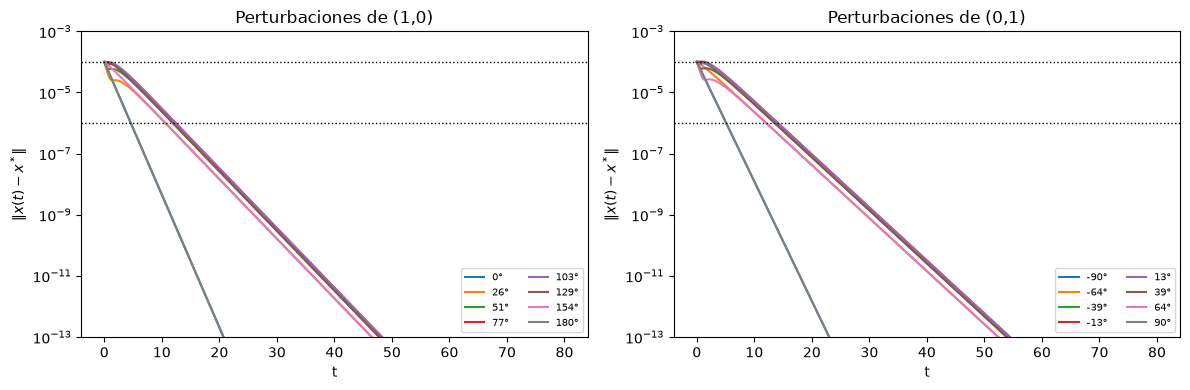

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (nombre, angulos) in zip(axes, casos.items()):
    for a in angulos:
        x0 = eq[nombre] + 1e-4 * np.array([np.cos(a), np.sin(a)])
        t, X = rk4(f, x0, 0.01, 80)
        ax.semilogy(t, np.linalg.norm(X - eq[nombre], axis=1), label=f"{np.degrees(a):.0f}°")
    ax.axhline(1e-6, color="k", ls=":", lw=1)
    ax.axhline(1e-4, color="k", ls=":", lw=1)
    ax.set_ylim(1e-13, 1e-3)
    ax.set_xlabel("t")
    ax.set_ylabel(r"$\|x(t) - x^*\|$")
    ax.set_title(f"Perturbaciones de {nombre}")
    ax.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

### Paso máximo de Euler

Para un valor propio real negativo, la condición $|1 + h\lambda| < 1$ da $h < 2/|\lambda|$ (derivación en el documento). Se busca numéricamente, por bisección, el mayor $h$ con el que Euler converge al equilibrio desde un estado cercano (distancia $10^{-3}$, dirección diagonal hacia el interior del cuadrante). Se considera que converge si, tras 20 000 pasos, la distancia al equilibrio es menor que $10^{-8}$.

In [13]:
def euler_converge(x_eq, x0, h, n_pasos=20000):
    with np.errstate(over="ignore", invalid="ignore"):
        _, X = euler(f, x0, h, n_pasos * h)
        d = np.linalg.norm(X[-1] - x_eq)
    return np.isfinite(d) and d < 1e-8


def h_max_numerico(x_eq, x0, a=0.5, b=3.0, tol=1e-6):
    while b - a > tol:
        m = (a + b) / 2
        if euler_converge(x_eq, x0, m):
            a = m
        else:
            b = m
    return (a + b) / 2


direccion = {"(1,0)": np.array([-1, 1]) / np.sqrt(2), "(0,1)": np.array([1, -1]) / np.sqrt(2)}
for nombre in ["(1,0)", "(0,1)"]:
    lam = clase[nombre]["λ"].real
    h_teo = (2 / np.abs(lam)).min()
    h_num = h_max_numerico(eq[nombre], eq[nombre] + 1e-3 * direccion[nombre])
    print(f"{nombre}: h_max teórico = {h_teo:.4f} | h_max numérico = {h_num:.4f} | "
          f"diferencia relativa = {abs(h_num - h_teo) / h_teo:.2%}")

(1,0): h_max teórico = 2.0000 | h_max numérico = 1.9994 | diferencia relativa = 0.03%


(0,1): h_max teórico = 2.2222 | h_max numérico = 2.2216 | diferencia relativa = 0.03%


**RESULTADOS**

El paso máximo numérico ($1.9994$ y $2.2216$) coincide con el teórico ($2$ y $2.2222$) con una diferencia de $0.03\%$, atribuible a la tolerancia del criterio de convergencia. Como el estado inicial está muy cerca del equilibrio, la linealización basta para predecir el comportamiento de Euler.

## Task 2.5. Intervenciones

### Campaña de adquisición ($\Delta$ usuarios de golpe)

In [14]:
etq_P2 = destino(f, np.array([ESTADOS["P2"]]), 0.05, 500, ATRACTORES)[0][0]
print(f"P2 converge a {NOMBRES_ATR[etq_P2]}")

P2 converge a (1,0): gana A


In [15]:
def destino_campana(delta):
    # Índice del atractor alcanzado desde P2 con delta usuarios extra para B
    p = np.array(ESTADOS["P2"]) + np.array([0, delta])
    return destino(f, np.array([p]), 0.05, 500, ATRACTORES)[0][0]


a, b = 0.0, 1.5
print(f"Δ = {a}: {NOMBRES_ATR[destino_campana(a)]} | Δ = {b}: {NOMBRES_ATR[destino_campana(b)]}")
while b - a > 1e-6:
    m = (a + b) / 2
    if destino_campana(m) == 0:
        a = m
    else:
        b = m
delta_min = (a + b) / 2
print(f"Δ mínimo ≈ {delta_min:.6f} -> nuevo estado inicial ({ESTADOS['P2'][0]}, {ESTADOS['P2'][1] + delta_min:.6f})")

y_front = np.interp(ESTADOS["P2"][0], frontera[:, 0], frontera[:, 1])
print(f"Frontera interpolada (bisección del Task 2.3) en x = 0.8: y = {y_front:.4f}")

Δ = 0.0: (1,0): gana A | Δ = 1.5: (0,1): gana B


Δ mínimo ≈ 0.637018 -> nuevo estado inicial (0.8, 0.937018)
Frontera interpolada (bisección del Task 2.3) en x = 0.8: y = 0.9361


**RESULTADOS**

Desde P2 el sistema va a $(1,0)$, así que la plataforma de interés es **B**. Sí existe un $\Delta$ mínimo: con $\Delta \approx 0.637$ el estado pasa a $(0.8, 0.937)$ y el destino cambia a $(0,1)$. El mapa de cuencas confirma que la frontera obtenida por bisección pasa por $y = 0.936$ en $x = 0.8$, justo debajo del nuevo estado.

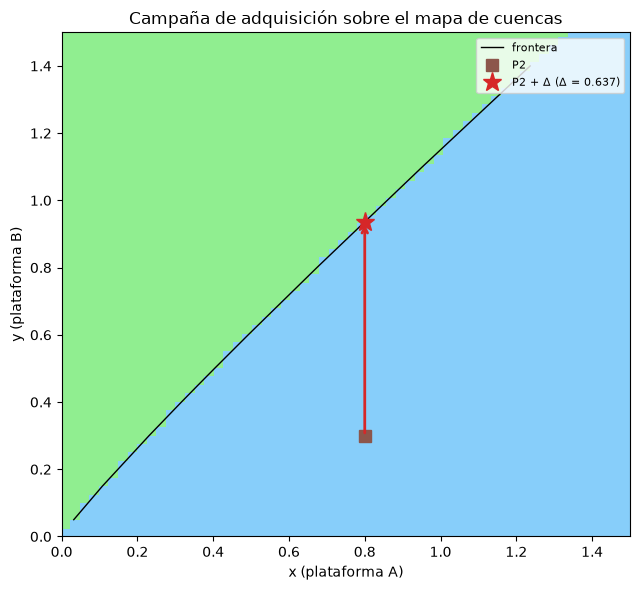

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.pcolormesh(MX, MY, cuenca, cmap=ListedColormap(["lightgray", "lightskyblue", "lightgreen"]),
              vmin=-1, vmax=1, shading="auto")
ax.plot(frontera[:, 0], frontera[:, 1], "k-", lw=1, label="frontera")
ax.annotate("", xy=(0.8, 0.3 + delta_min), xytext=(0.8, 0.3),
            arrowprops=dict(arrowstyle="->", lw=2, color="tab:red"))
ax.plot(*ESTADOS["P2"], "s", color="tab:brown", ms=9, label="P2")
ax.plot(0.8, 0.3 + delta_min, "*", color="tab:red", ms=14, label=f"P2 + Δ (Δ = {delta_min:.3f})")
ax.set_xlim(0, 1.5)
ax.set_ylim(0, 1.5)
ax.set_xlabel("x (plataforma A)")
ax.set_ylabel("y (plataforma B)")
ax.set_title("Campaña de adquisición sobre el mapa de cuencas")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

### Diferenciación del producto (reducir $\alpha_{21}$)

El valor propio de $(1,0)$ en la dirección de B es $\lambda = r_2(1 - \alpha_{21})$, que cambia de signo en $\alpha_{21} = 1$ (derivación en el documento). Se simula a cada lado del valor crítico desde un estado muy cercano a $(1,0)$, $(0.99, 0.01)$, para ver si $(1,0)$ sigue siendo estable. También se reporta el destino desde P2.

α21 = 0.9: λ de (1,0) en dirección de B = +0.090 | desde (0.99, 0.01) -> (0.0000, 1.0000) | desde P2 -> (0.0000, 1.0000)


α21 = 1.1: λ de (1,0) en dirección de B = -0.090 | desde (0.99, 0.01) -> (1.0000, 0.0000) | desde P2 -> (0.0000, 1.0000)


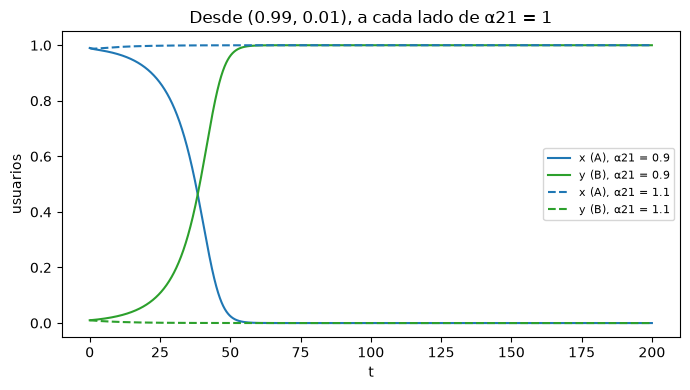

In [17]:
CERCA_A = np.array([0.99, 0.01])
fig, ax = plt.subplots(figsize=(7, 4))
for a21, estilo in [(0.9, "-"), (1.1, "--")]:
    fa = lambda x, a21=a21: campo(x, A12, a21, R1, R2)
    _, X = rk4(fa, CERCA_A, 0.01, 200)
    _, XP2 = rk4(fa, np.array(ESTADOS["P2"]), 0.01, 200)
    print(f"α21 = {a21}: λ de (1,0) en dirección de B = {R2 * (1 - a21):+.3f} | "
          f"desde (0.99, 0.01) -> ({X[-1, 0]:.4f}, {X[-1, 1]:.4f}) | desde P2 -> ({XP2[-1, 0]:.4f}, {XP2[-1, 1]:.4f})")
    t = np.linspace(0, 200, X.shape[0])
    ax.plot(t, X[:, 0], estilo, color="tab:blue", label=f"x (A), α21 = {a21}")
    ax.plot(t, X[:, 1], estilo, color="tab:green", label=f"y (B), α21 = {a21}")
ax.set_xlabel("t")
ax.set_ylabel("usuarios")
ax.set_title("Desde (0.99, 0.01), a cada lado de α21 = 1")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**RESULTADOS**

Con $\alpha_{21} = 1.1$ el valor propio es negativo ($-0.09$): $(1,0)$ sigue siendo estable y el estado cercano regresa a él (régimen biestable). Con $\alpha_{21} = 0.9$ el valor propio es positivo ($+0.09$): $(1,0)$ se vuelve inestable y el sistema se va a $(0,1)$. El valor crítico es $\alpha_{21} = 1$. Desde P2, ambos valores llevan a $(0,1)$: con $\alpha_{21} = 1.1$ no cambia el régimen, pero sí se mueve la frontera de las cuencas.

### Robustez de cada intervención

Se mide el tiempo que tarda el sistema en llegar a $(0,1)$ (distancia menor que $10^{-4}$):

- **Campaña:** desde P2 + $\Delta$, con $\Delta$ un poco por encima del mínimo.
- **Diferenciación:** desde $(0.99, 0.01)$, con $\alpha_{21}$ por debajo de 1. Se reporta también $1/|\lambda|$ del valor propio de $(1,0)$ en la dirección de B.

In [18]:
for factor in [1.01, 1.1, 1.5]:
    p = np.array(ESTADOS["P2"]) + np.array([0, factor * delta_min])
    etq, tc = destino(f, np.array([p]), 0.05, 2000, ATRACTORES)
    print(f"Campaña Δ = {factor:.2f}·Δmin = {factor * delta_min:.3f}: destino {NOMBRES_ATR[etq[0]]}, tiempo = {tc[0]:.1f}")

for a21 in [0.99, 0.95, 0.9, 0.8]:
    fa = lambda x, a21=a21: campo(x, A12, a21, R1, R2)
    etq, tc = destino(fa, np.array([CERCA_A]), 0.05, 5000, [eq["(1,0)"], eq["(0,1)"]])
    lam_B = R2 * (1 - a21)
    print(f"Diferenciación α21 = {a21}: λ = {lam_B:+.3f}, 1/|λ| = {1 / lam_B:6.1f}, "
          f"destino {NOMBRES_ATR[etq[0]]}, tiempo = {tc[0]:.1f}")

Campaña Δ = 1.01·Δmin = 0.643: destino (0,1): gana B, tiempo = 53.8
Campaña Δ = 1.10·Δmin = 0.701: destino (0,1): gana B, tiempo = 40.7
Campaña Δ = 1.50·Δmin = 0.956: destino (0,1): gana B, tiempo = 31.9


Diferenciación α21 = 0.99: λ = +0.009, 1/|λ| =  111.1, destino (0,1): gana B, tiempo = 175.2


Diferenciación α21 = 0.95: λ = +0.045, 1/|λ| =   22.2, destino (0,1): gana B, tiempo = 89.6
Diferenciación α21 = 0.9: λ = +0.090, 1/|λ| =   11.1, destino (0,1): gana B, tiempo = 65.6


Diferenciación α21 = 0.8: λ = +0.180, 1/|λ| =    5.6, destino (0,1): gana B, tiempo = 48.7


### Recomendación

Se recomienda la **diferenciación del producto**, reduciendo $\alpha_{21}$ con margen por debajo de 1.

- **Campaña:** el sistema sigue siendo biestable y $(1,0)$ sigue siendo estable (tiempo de recuperación $2.22$). El éxito depende de quedar del lado correcto de la frontera, cuya posición depende de todos los parámetros; un error pequeño al estimarlos puede dejar el estado del lado de A. Además, con $\Delta$ cerca del mínimo el sistema pasa cerca de la silla, cuyo valor propio inestable ($0.173$) es pequeño: tarda $53.8$ en llegar a $(0,1)$, contra $31.9$ con $\Delta = 1.5\,\Delta_{\min}$, y durante ese tiempo una perturbación lo puede regresar.
- **Diferenciación:** con $\alpha_{21} < 1$, $(1,0)$ deja de ser estable y $(0,1)$ es el único destino estable, sin importar el estado inicial. Su tiempo de recuperación ($2.5$) no depende de $\alpha_{21}$, porque sus valores propios son $r_1(1 - \alpha_{12}) = -0.4$ y $-r_2 = -0.9$. El riesgo está cerca del valor crítico: con $\alpha_{21} = 0.99$ el valor propio de $(1,0)$ es $+0.009$, casi sobre el eje imaginario, y el cambio tarda $175.2$; además, un error de estimación de $0.01$ dejaría el régimen sin cambiar. Con $\alpha_{21} = 0.8$ el valor propio es $+0.18$ y el cambio tarda $48.7$.

Por lo tanto, la diferenciación es más robusta siempre que lleve $\alpha_{21}$ a un valor claramente menor que 1, de modo que el valor propio de $(1,0)$ quede lejos del eje imaginario.